In [75]:
import sys
import os

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

from scripts.functions import load_data

In [76]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error, r2_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso

## Import Data

In [77]:
data, features = load_data()

## Split Data and Create Linear Model

In [78]:
train, test = train_test_split(data, test_size = 0.2, random_state=42)

## Standardize Features

lr = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LinearRegression())])

## Linear Model trained on Molecular Weight 

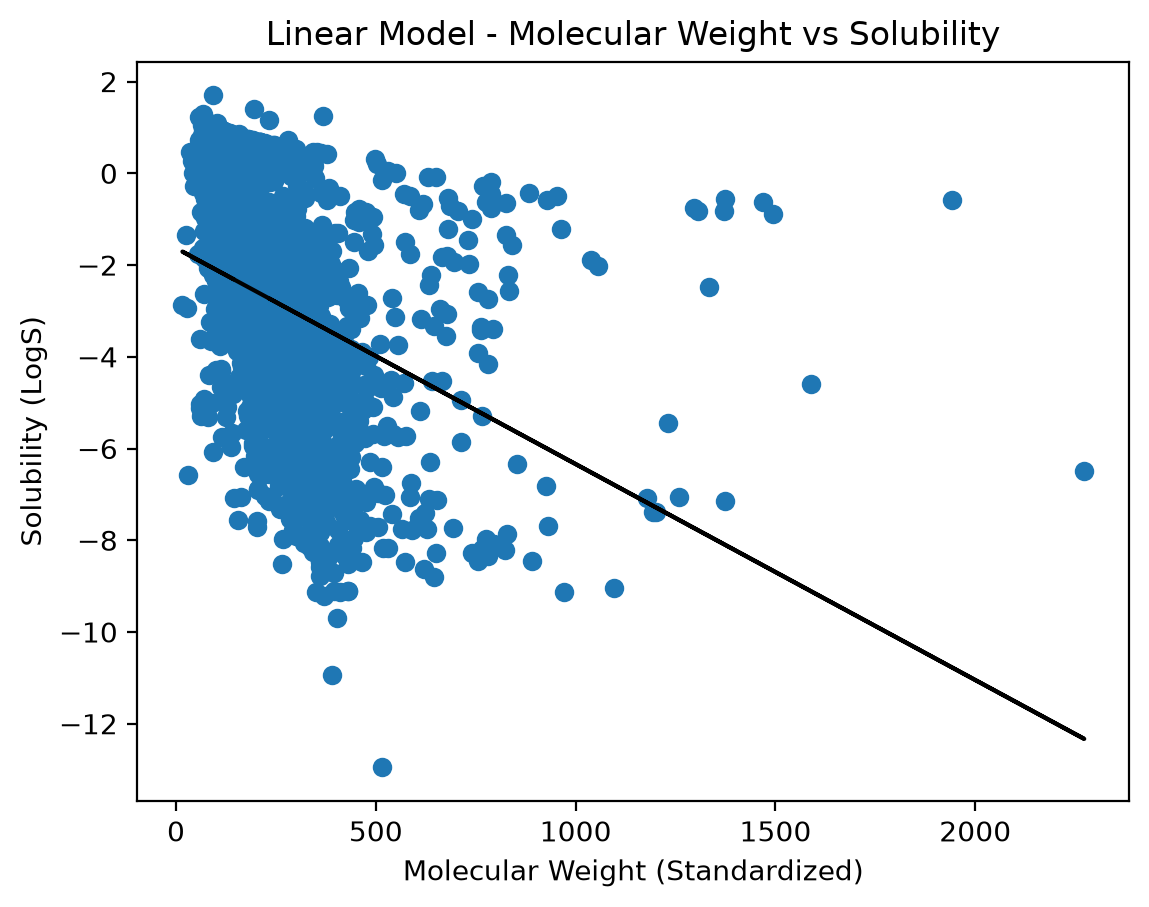

In [79]:
X_train, y_train = train[["MolWt"]], train["Solubility"]
X_test, y_test = test[["MolWt"]], test["Solubility"]

lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

root_mean_squared_error(y_test, y_pred)
r2_score(y_test, y_pred)

plt.scatter(X_test, y_test)
plt.plot(X_test, y_pred, 'black')
plt.title("Linear Model - Molecular Weight vs Solubility")
plt.xlabel("Molecular Weight (Standardized)")
plt.ylabel("Solubility (LogS)")
plt.show()

## Linear Model trained on Octanol-Water Partition Coefficient

The root mean squared error: 1.7892
The Pearson Correlation Coefficient (R^2): 0.4099


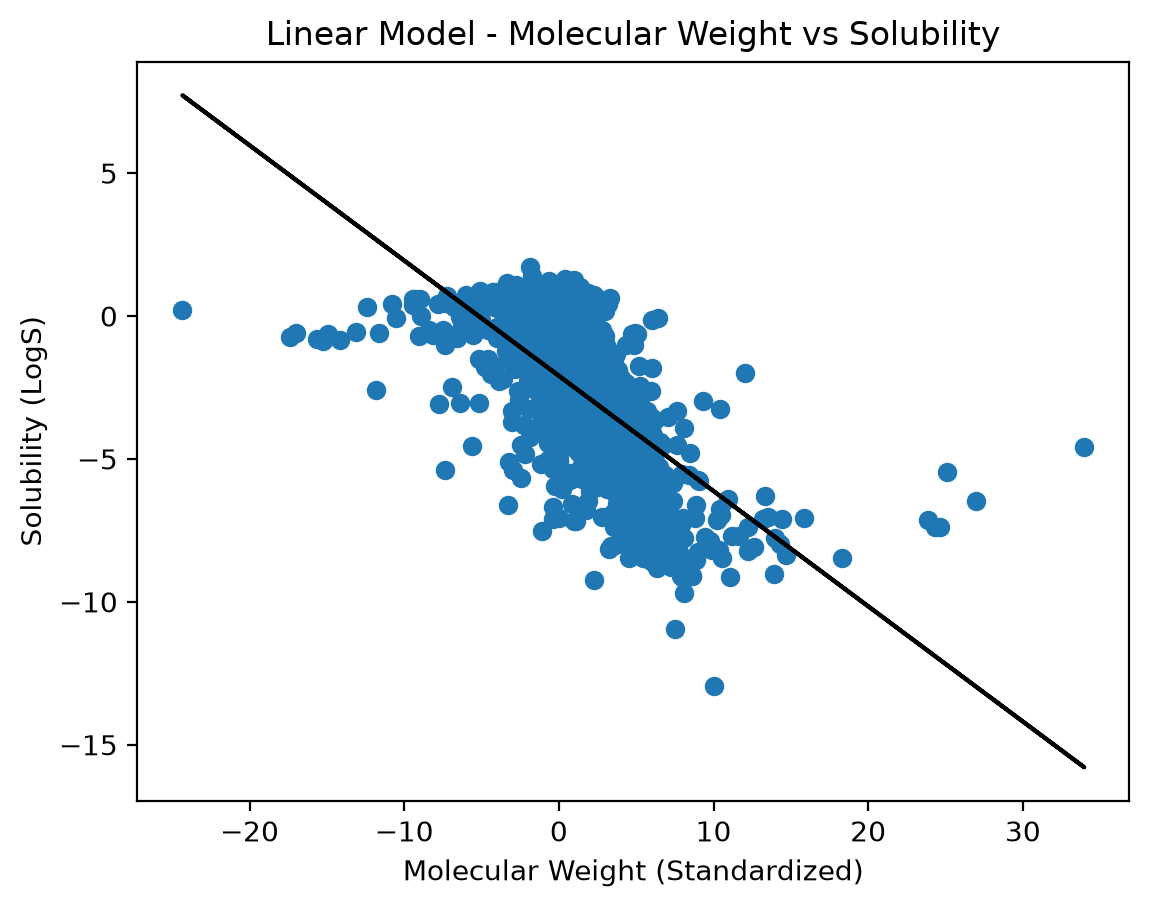

In [80]:
X_train, y_train = train[["MolLogP"]], train["Solubility"]
X_test, y_test = test[["MolLogP"]], test["Solubility"]

lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

print(f"The root mean squared error: {round(root_mean_squared_error(y_test, y_pred), 4)}")
print(f"The Pearson Correlation Coefficient (R^2): {round(r2_score(y_test, y_pred), 4)}")

plt.scatter(X_test, y_test)
plt.plot(X_test, y_pred, 'black')
plt.title("Linear Model - Molecular Weight vs Solubility")
plt.xlabel("Molecular Weight (Standardized)")
plt.ylabel("Solubility (LogS)")
plt.show()

## Hyperparameter (Alpha) Tuning

In [ ]:
train, test = train_test_split(data, test_size = 0.2, random_state=42)

X, y = train[features], train["Solubility"]
X_test, y_test = test[features], test["Solubility"]

In [82]:
alphas = np.logspace(-2, 0.5, 100)

rmse_list = []
r2_list = []
for alpha in alphas:
    lasso = Pipeline([
        ('scaler', StandardScaler()),
        ('lasso', Lasso(alpha = alpha))])
    lasso.fit(X, y)
    preds = lasso.predict(X_test)
    rmse = root_mean_squared_error(preds, y_test)
    r2 = r2_score(preds, y_test)
    rmse_list.append(rmse)
    r2_list.append(r2)

min_idx = np.argmin(rmse_list)
print(f"The alpha with the lowest rmse was {alphas[min_idx]}")

The alpha with the lowest rmse was 0.01


Text(0.5, 1.0, 'Tuning Hyperparameters for Lasso\nRMSE vs Alpha')

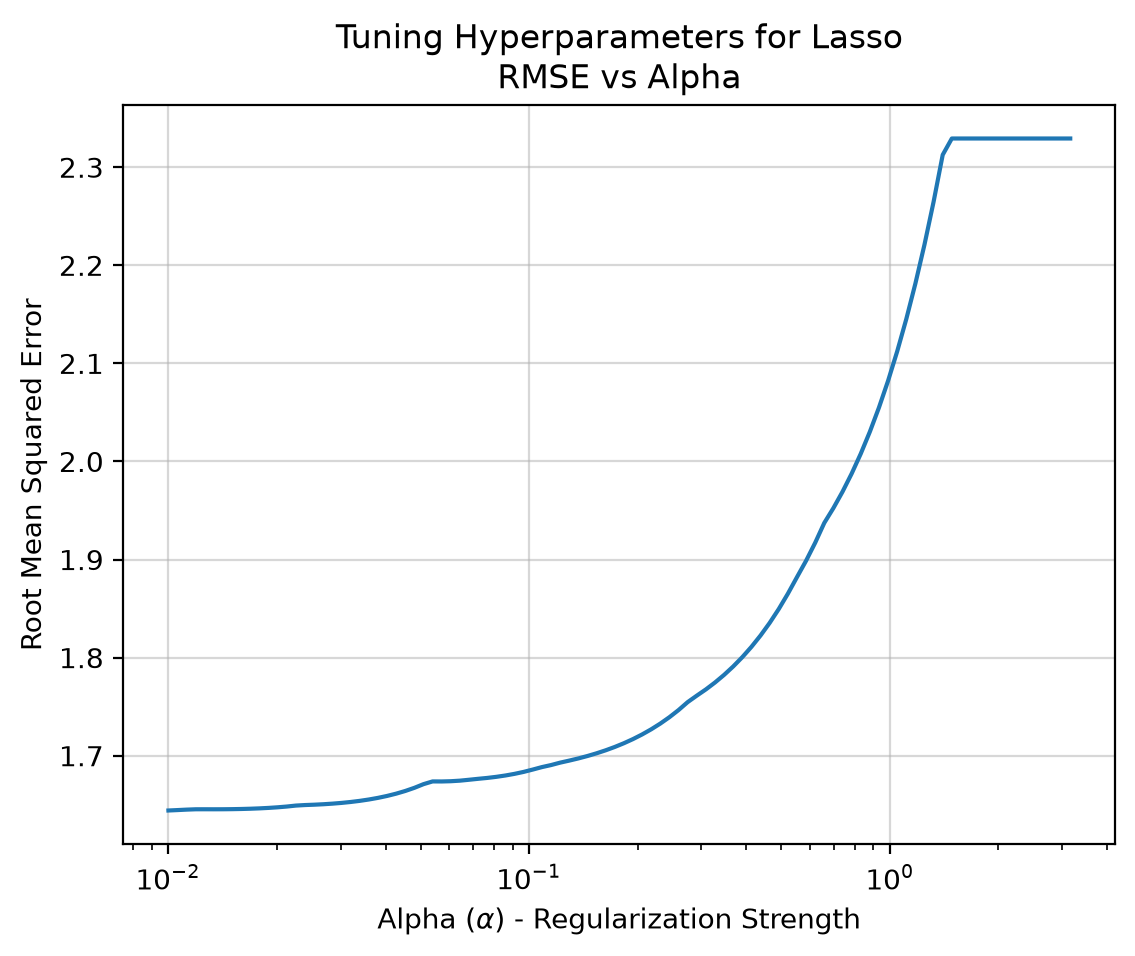

In [83]:
fig, ax = plt.subplots()

ax.plot(alphas, rmse_list)
ax.set_xscale("log")
ax.grid(alpha = 0.5)
ax.set_xlabel(r"Alpha ($\alpha$) - Regularization Strength")
ax.set_ylabel("Root Mean Squared Error")
ax.set_title("Tuning Hyperparameters for Lasso" + "\n" + "RMSE vs Alpha")

# Lasso Model

In [89]:
lasso = Pipeline([
    ('scaler', StandardScaler()),
    ('lasso', Lasso(alpha = 0.01))])

lasso.fit(X, y)
y_pred = lasso.predict(X_test)

rmse = root_mean_squared_error(y_test, y_pred) 
r2 = r2_score(y_test, y_pred)
print(f"The root mean squared error is {round(rmse,4)}")
print(f"The correlation coefficient is {round(r2,4)}")

The root mean squared error is 1.6441
The correlation coefficient is 0.5017


## Feature Decay with Regularization Strength

In [85]:
coefficients = []
for alpha in alphas:
    lasso = Pipeline([
        ('scaler', StandardScaler()),
        ('lasso', Lasso(alpha = alpha))])
    lasso.fit(X, y)
    coefficients.append(lasso['lasso'].coef_)

coefficients = np.array(coefficients)
coeffs = {feat: coefficients[:, i] for i, feat in enumerate(features)}

In [86]:
feat_areas = {feat: np.trapezoid(np.abs(coefs), x=np.log10(alphas)) for feat, coefs in coeffs.items()}
sorted_features = sorted(feat_areas.items(), key=lambda item: item[1], reverse=True)
top_feats = [feature[0] for feature in sorted_features[:7]]

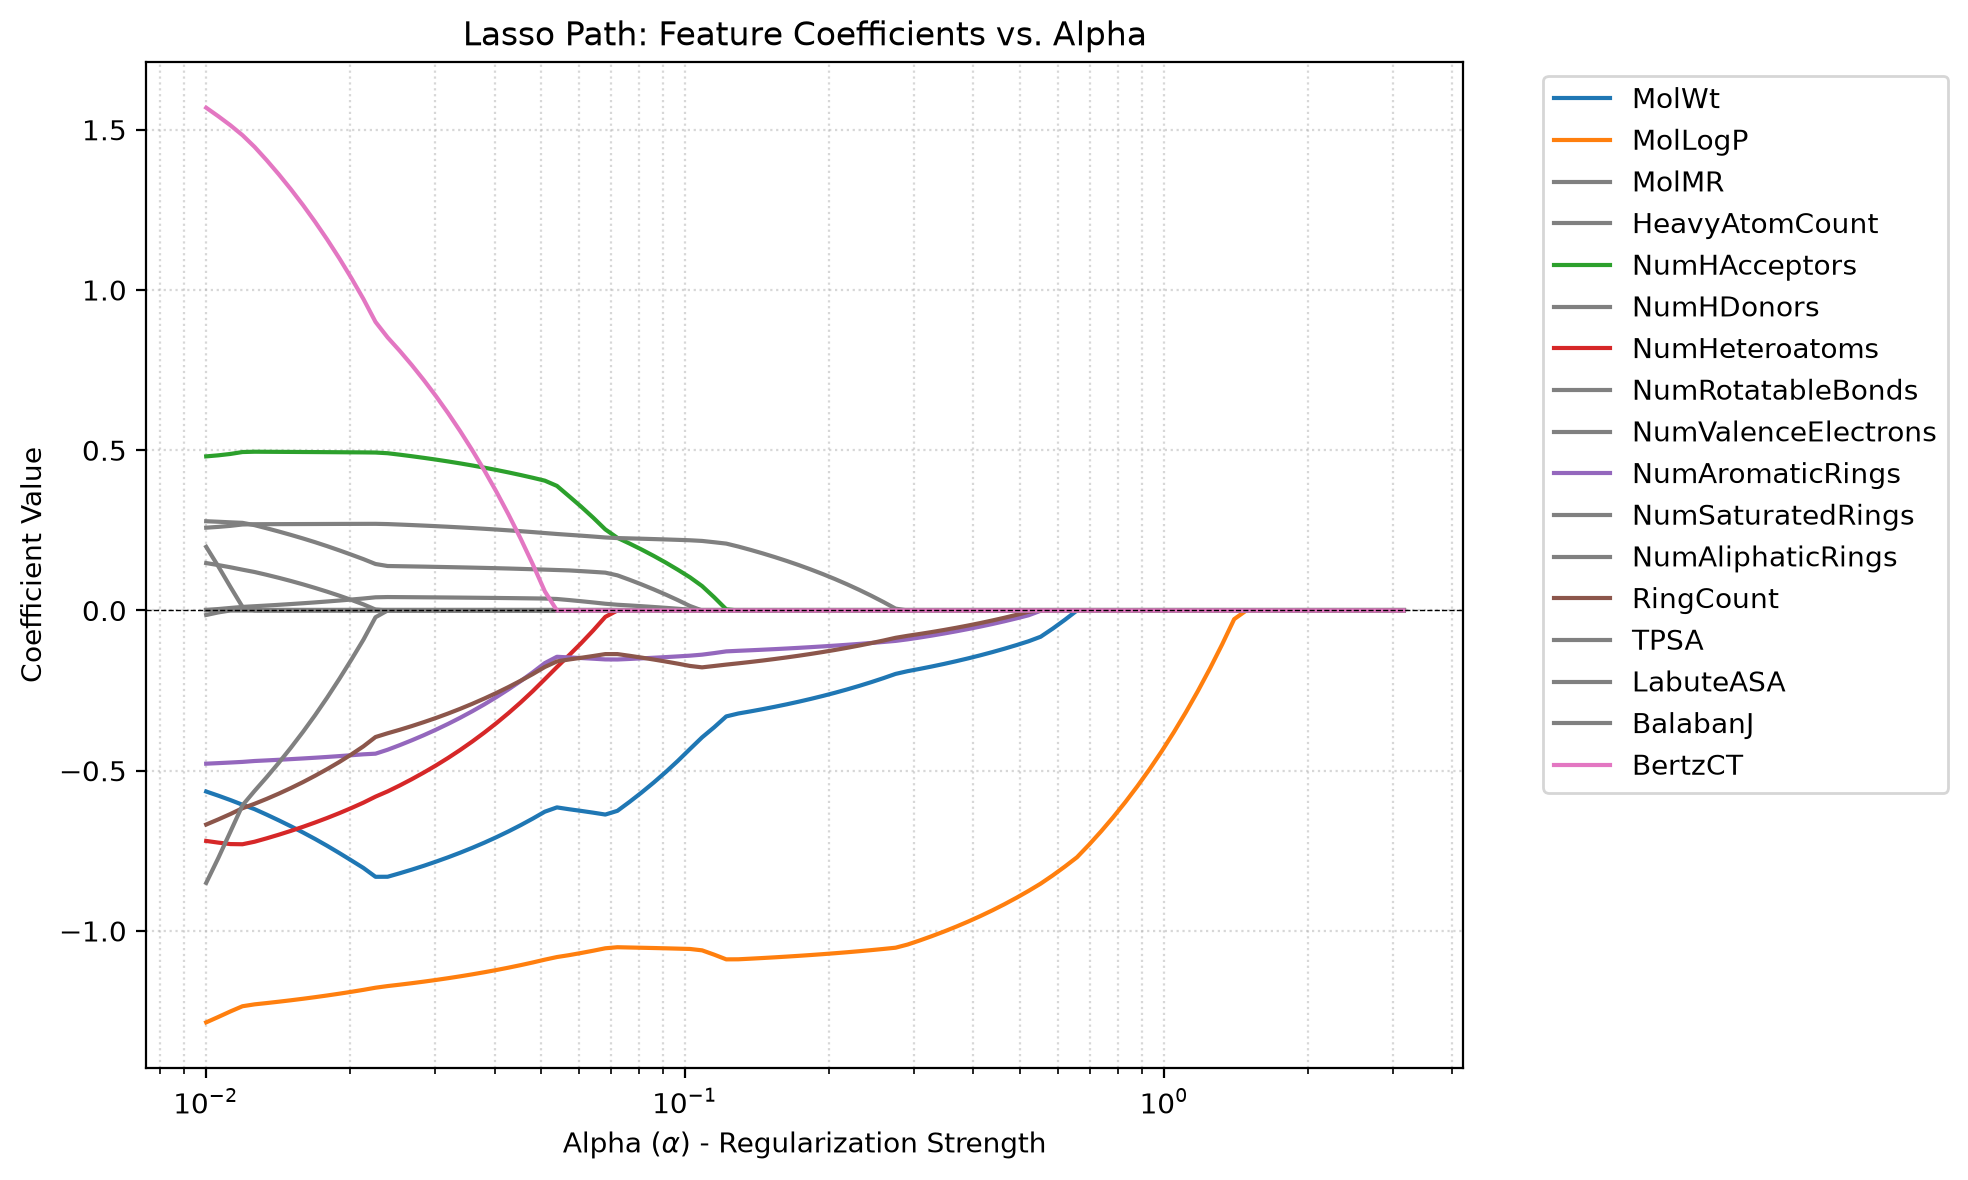

In [87]:
plt.figure(figsize=(10, 6))
for feat, coeff in coeffs.items():
    if feat in top_feats:
        plt.plot(alphas, coeff, label=feat)
    else:
        plt.plot(alphas, coeff, label = feat, color = 'grey')

plt.xscale("log")
plt.xlabel(r"Alpha ($\alpha$) - Regularization Strength")
plt.ylabel("Coefficient Value")
plt.title("Lasso Path: Feature Coefficients vs. Alpha")
plt.axhline(0, color="black", linestyle="--", linewidth=0.5)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, which="both", linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()